In [1]:
import os
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import re
import nibabel as nib
import matplotlib.pyplot as plt
import cv2
import pandas as pd

####deteccion rutas archivos según regex
def busqueda_rutas(cadena):
        directorio_imagenes = './NIFTI PREPROC'
        rutas_imagenes = [os.path.join(directorio_imagenes, imagen) for imagen in os.listdir(directorio_imagenes)]
        patron = re.compile(fr'.*({cadena})')
        seleccionados = [s for s in rutas_imagenes if re.search(patron, s)]

        return seleccionados

def formacion_trios(lista1, lista2, lista3):

        patron = re.compile(r'.*(H9O)')
        h9O_list = [s for s in lista1 + lista2 + lista3 if re.search(patron, s)]
        
        patron = re.compile(r'.*(HVN)')
        hvn_list = [s for s in lista1 + lista2 + lista3 if re.search(patron, s)]

        #Obtenemos un listado con los números de paciente presentes en cada hospital
        pacientes_9O = []
        trios_9O = []
        indices_bad_h9O = []
        for ruta in h9O_list:
                ruta_sp = ruta.split('_')
                paciente = ruta_sp[1]

                paciente_sp = paciente[1] + paciente[2]
                pacientes_9O.append(paciente_sp)
        for index, pac9O in enumerate(np.unique(np.array(pacientes_9O))):
                patron = re.compile(fr'.*({pac9O})')
                seleccion = [s for s in h9O_list if re.search(patron, s)]
                seleccion.sort()
                # print(seleccion)
                trios_9O.append(seleccion)
                if(len(seleccion) < 3):
                       indices_bad_h9O.append(index)
       
        pacientes_hvn = []
        trios_hvn = []
        indices_bad_hvn = []
        for ruta in hvn_list:
                ruta_sp = ruta.split('_')
                paciente = ruta_sp[1]

                paciente_sp = paciente[1] + paciente[2]
                pacientes_hvn.append(paciente_sp)
        for index, pac_hvn in enumerate(np.unique(np.array(pacientes_hvn))):
                patron = re.compile(fr'.*({pac_hvn})')
                seleccion = [s for s in hvn_list if re.search(patron, s)]
                seleccion.sort()
                # print(seleccion)
                trios_hvn.append(seleccion)
                if(len(seleccion) < 3):
                       indices_bad_hvn.append(index)
        
        # print(f"TOTALES BUENOS H9O: {len(trios_9O) - len(indices_bad_h9O)}")
        # print(f"TOTALES BUENOS HVN: {len(trios_hvn) - len(indices_bad_hvn)}")
        
        for indice in sorted(indices_bad_h9O, reverse=True):
                del trios_9O[indice]
        for indice in sorted(indices_bad_hvn, reverse=True):
                del trios_hvn[indice]
        
        return [trios_9O, trios_hvn]

def rangeDisplay01(im, flag_GLOBAL= True):
  im = im.astype(float)
  if flag_GLOBAL:
    im = (im - im.min())/(im.max() - im.min())
  else:
    # bands normalization
    for band in range(im.shape[2]):
      im[:, :, band] = (im[:, :, band] - im[:, :, band].min())/(im[:, :, band].max() - im[:, :, band].min())
      # Note: remember that, for plt.imshow with RGB data, the valid range is [0..1] for floats and [0..255] for integers.
  return im

def displayIm(im, title='Result',factor= 2):
  # First normalize range
  max=np.max(im)
  min=np.min(im)
  if min<0 or max>255:
    im=rangeDisplay01(im,flag_GLOBAL=True)
  if len(im.shape) == 3:
    # im has three-channels
    plt.imshow(im, cmap='jet')
  else:
    # im has a single-channel
    plt.imshow(im, cmap='gray')
  figure_size = plt.gcf().get_size_inches()
  plt.gcf().set_size_inches(factor * figure_size)
  plt.title(title)
  plt.xticks([]), plt.yticks([])
  plt.show()

def lectura_img(trios, modo):
        imgs_nifti = []
        pacs = []
        hosp = []
        for trio in trios:
                        trio_np = []
                        paciente = trio[0].split("_")[1]
                        hospital = trio[0].split("_")[2].split(".")[0]
                        
                        for ruta in trio:
                                # Cargar la imagen NIfTI
                                imagen_nifti = nib.load(ruta)
                                
                                imagen_nifti = imagen_nifti.get_fdata()
                                ##se sutitutyen los nan por 0
                                imagen_nifti = np.nan_to_num(imagen_nifti, nan=0.0)
                                trio_np.append(imagen_nifti)
                        imgs_nifti.append(trio_np)
                        pacs.append(paciente)
                        hosp.append(hospital)

        if(modo == 4):
                imgs_final = []
                ##Rehacer para mosaico
                ##para hacer mosaico debemos obtener el número de imágenes
                ##debe ser para para que no quede ninguna zona hueca
                ##si se hace la division entera de la longitud de canales entre los trozos en que queremos partir la imagen, se obtiene el step
                ##es decir, la primera media sería 0 a step-1, la siguiente de step a step*2-1, etc, etc. En el final, pueden estar incluido más canales

                elems2d = [] 
                for trio_np in imgs_nifti:
                        
                        parte = []
                        for elem in trio_np:
                                # Dividimos el arreglo en base a su profundidad
                                img1 = elem[:,:,0::4]
                                img2 = elem[:,:,1::4]
                                img3 = elem[:,:,2::4]
                                img4 = elem[:,:,3::4]

                                parte.append(np.mean(img1, axis=2))
                                parte.append(np.mean(img2, axis=2))
                                parte.append(np.mean(img3, axis=2))
                                parte.append(np.mean(img4, axis=2))
                        elems2d.append(parte)
                            ###Si es 4, se apilan 2 a 2 horizontalmente y despues el resultado en vertical
                             ###si es 6, 3 y 3 y así sucesivamente
                for parte in elems2d:
                    print(len(elems2d))
                    for index in range(0,len(parte), modo*3):
                     imagen1 = np.stack((parte[index], parte[index+modo], parte[index+modo*2]), axis=2)
                     imagen2 = np.stack((parte[index+1], parte[index+1+modo], parte[index+1+modo*2]), axis=2)
                     imagen3 = np.stack((parte[index+2], parte[index+2+modo], parte[index+2+modo*2]), axis=2)
                     imagen4 = np.stack((parte[index+3], parte[index+3+modo], parte[index+3+modo*2]), axis=2)
                     imgs_final.append(imagen1)
                     imgs_final.append(imagen2)
                     imgs_final.append(imagen3)
                     imgs_final.append(imagen4)
                return imgs_final, pacs, hosp

In [2]:
rutas_a90 = busqueda_rutas('A90')

rutas_fdg = busqueda_rutas('FDG')
rutas_1ct = busqueda_rutas('1CT')
trios = formacion_trios(rutas_a90, rutas_fdg, rutas_1ct)

imagenes_media_1, pac_media_1, hosp_media_1  = lectura_img(trios[0], 4)

imagenes_media_2, pac_media_2, hosp_media_2  = lectura_img(trios[1], 4)

##Las imágenes en grupos de 4, pertenencen al mismo paciente y hospital

ruta_guardado1 = "./IMGS_MEDIA_AMPL_2"
df = pd.read_csv('etiquetas.txt', delimiter='\t')
df = df.dropna(how="all")

# Asegate de que el directorio exista
if not os.path.exists(ruta_guardado1):
        os.makedirs(ruta_guardado1)
else:
# Si el directorio ya existe, borra su contenido
        for archivo in os.listdir(ruta_guardado1):
                archivo_ruta = os.path.join(ruta_guardado1, archivo)
                os.remove(archivo_ruta)

for i in range(0, len(imagenes_media_1), 4):
      
        # displayIm(im[:,:,2])
        im1 = rangeDisplay01(imagenes_media_1[i], False)
        im2 = rangeDisplay01(imagenes_media_1[i+1], False)
        im3 = rangeDisplay01(imagenes_media_1[i+2], False)
        im4 = rangeDisplay01(imagenes_media_1[i+3], False)
        im1 = im1.astype(np.float32)
        im2 = im2.astype(np.float32)
        im3 = im3.astype(np.float32)
        im4 = im4.astype(np.float32)
        etiqueta = df.loc[(df['Pac'] == pac_media_1[i//4]) & (df['Centro'] == hosp_media_1[i//4]), 'Etiqueta'].values
        if (etiqueta != 2):
                # im = im.transpose(1, 2, 0)           
                cv2.imwrite(f"{ruta_guardado1}/_{pac_media_1[i//4]}_{hosp_media_1[i//4]}_{int(etiqueta[0]+1)}_1.jpg", cv2.cvtColor(im1*255, cv2.COLOR_RGB2BGR))
                cv2.imwrite(f"{ruta_guardado1}/_{pac_media_1[i//4]}_{hosp_media_1[i//4]}_{int(etiqueta[0]+3)}_2.jpg", cv2.cvtColor(im2*255, cv2.COLOR_RGB2BGR))
                cv2.imwrite(f"{ruta_guardado1}/_{pac_media_1[i//4]}_{hosp_media_1[i//4]}_{int(etiqueta[0]+5)}_3.jpg", cv2.cvtColor(im3*255, cv2.COLOR_RGB2BGR))
                cv2.imwrite(f"{ruta_guardado1}/_{pac_media_1[i//4]}_{hosp_media_1[i//4]}_{int(etiqueta[0]+7)}_4.jpg", cv2.cvtColor(im4*255, cv2.COLOR_RGB2BGR))
for i in range(0, len(imagenes_media_2), 4):
      
        # displayIm(im[:,:,2])
        im1 = rangeDisplay01(imagenes_media_2[i], False)
        im2 = rangeDisplay01(imagenes_media_2[i+1], False)
        im3 = rangeDisplay01(imagenes_media_2[i+2], False)
        im4 = rangeDisplay01(imagenes_media_2[i+3], False)
        im1 = im1.astype(np.float32)
        im2 = im2.astype(np.float32)
        im3 = im3.astype(np.float32)
        im4 = im4.astype(np.float32)
        etiqueta = df.loc[(df['Pac'] == pac_media_2[i//4]) & (df['Centro'] == hosp_media_2[i//4]), 'Etiqueta'].values
        if (etiqueta != 2):
                # im = im.transpose(1, 2, 0)           
                cv2.imwrite(f"{ruta_guardado1}/_{pac_media_2[i//4]}_{hosp_media_2[i//4]}_{int(etiqueta[0]+1)}_1.jpg", cv2.cvtColor(im1*255, cv2.COLOR_RGB2BGR))
                cv2.imwrite(f"{ruta_guardado1}/_{pac_media_2[i//4]}_{hosp_media_2[i//4]}_{int(etiqueta[0]+3)}_2.jpg", cv2.cvtColor(im2*255, cv2.COLOR_RGB2BGR))
                cv2.imwrite(f"{ruta_guardado1}/_{pac_media_2[i//4]}_{hosp_media_2[i//4]}_{int(etiqueta[0]+5)}_3.jpg", cv2.cvtColor(im3*255, cv2.COLOR_RGB2BGR))
                cv2.imwrite(f"{ruta_guardado1}/_{pac_media_2[i//4]}_{hosp_media_2[i//4]}_{int(etiqueta[0]+7)}_4.jpg", cv2.cvtColor(im4*255, cv2.COLOR_RGB2BGR))

22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23


In [3]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms, utils
from torchvision.transforms import v2
import re
# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA version: 12.1
Using device: cuda


In [4]:
import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MEDIA_AMPL_2'

# Obtener la ruta absoluta del directorio
directorio_absoluto = os.path.abspath(directorio)

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio_absoluto)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio_absoluto, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean_a_2 = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean_a_2)

                                                  Ruta  Etiqueta
0    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         2
1    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         4
2    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         6
3    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         8
4    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         2
..                                                 ...       ...
171  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         8
172  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         1
173  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         3
174  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         5
175  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         7

[176 rows x 2 columns]


[24 20 24 20 24 20 24 20]


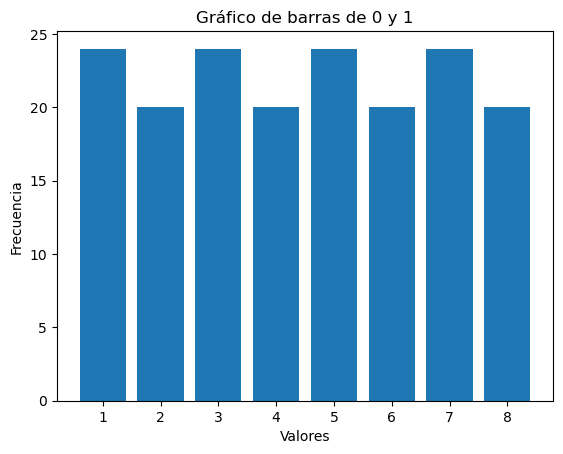

In [5]:
###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_mean_a_2["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()

                                    Ruta  Etiqueta
0   ./IMGS_MEDIA_AMPL_2\_P15_HVN_1_1.jpg         1
1   ./IMGS_MEDIA_AMPL_2\_P15_HVN_3_2.jpg         3
2   ./IMGS_MEDIA_AMPL_2\_P15_HVN_5_3.jpg         5
3   ./IMGS_MEDIA_AMPL_2\_P15_HVN_7_4.jpg         7
4   ./IMGS_MEDIA_AMPL_2\_P60_HVN_2_1.jpg         2
5   ./IMGS_MEDIA_AMPL_2\_P60_HVN_4_2.jpg         4
6   ./IMGS_MEDIA_AMPL_2\_P60_HVN_6_3.jpg         6
7   ./IMGS_MEDIA_AMPL_2\_P60_HVN_8_4.jpg         8
8   ./IMGS_MEDIA_AMPL_2\_P47_HVN_1_1.jpg         1
9   ./IMGS_MEDIA_AMPL_2\_P47_HVN_3_2.jpg         3
10  ./IMGS_MEDIA_AMPL_2\_P47_HVN_5_3.jpg         5
11  ./IMGS_MEDIA_AMPL_2\_P47_HVN_7_4.jpg         7
12  ./IMGS_MEDIA_AMPL_2\_P17_HVN_1_1.jpg         1
13  ./IMGS_MEDIA_AMPL_2\_P17_HVN_3_2.jpg         3
14  ./IMGS_MEDIA_AMPL_2\_P17_HVN_5_3.jpg         5
15  ./IMGS_MEDIA_AMPL_2\_P17_HVN_7_4.jpg         7
16  ./IMGS_MEDIA_AMPL_2\_P26_HVN_1_1.jpg         1
17  ./IMGS_MEDIA_AMPL_2\_P26_HVN_3_2.jpg         3
18  ./IMGS_MEDIA_AMPL_2\_P26_HV


ETIQUETAS 0: 2.0*4
ETIQUETAS 1: 1.75*4


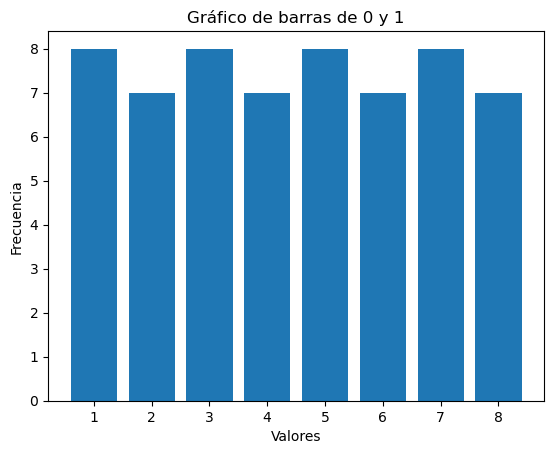

In [6]:
##A partir de aqui, se separa el conjunto de test de forma aleatoria, dada lo balanceadas que están las clases, se espera que test también lo este
from sklearn.model_selection import train_test_split

import random

# Vector de pacientes y de 2 strings
pacientes = [f'{i:02}' for i in range(2, 76)]
strings = ['HVN', 'H9O']
# Número de combinaciones que deseas crear
num_combinaciones = 15
combinaciones_totales = 0
# Lista para almacenar las combinaciones
combinaciones = []

random.seed(20)
 # Obtener la lista de nombres de archivos que coinciden con la expresión regular
nombres_de_archivos = os.listdir('./IMGS_MEDIA_AMPL_2')  # Reemplaza '*' con el directorio o patrón adecuado si es necesario
# Crear 15 combinaciones aleatorias

while combinaciones_totales < 15:
    # Seleccionar un paciente aleatorio
    
    paciente_aleatorio = random.choice(pacientes)
    
    # Seleccionar un string aleatorio
    string_aleatorio = random.choice(strings)
    
    # Expresión regular para filtrar nombres de archivos
    expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

    # Filtrar los nombres de archivos que coinciden con la expresión regular
    archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]
    if (len(archivos_coincidentes) == 4):
        combinaciones.extend(archivos_coincidentes)
        combinaciones_totales += 1
        pacientes.remove(paciente_aleatorio)

data = []
# Iterar sobre los archivos
for archivo in combinaciones:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))
        
    nombres_de_archivos.remove(archivo)
    
    
# Crear el DataFrame de Pandas
df_test = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_test)

###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_test["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)
print(F"ETIQUETAS 0: {contador[0]/4}*4")
print(F"ETIQUETAS 1: {contador[1]/4}*4")

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()


                                     Ruta  Etiqueta
0    ./IMGS_MEDIA_AMPL_2\_P08_HVN_2_1.jpg         2
1    ./IMGS_MEDIA_AMPL_2\_P08_HVN_4_2.jpg         4
2    ./IMGS_MEDIA_AMPL_2\_P08_HVN_6_3.jpg         6
3    ./IMGS_MEDIA_AMPL_2\_P08_HVN_8_4.jpg         8
4    ./IMGS_MEDIA_AMPL_2\_P10_HVN_2_1.jpg         2
..                                    ...       ...
111  ./IMGS_MEDIA_AMPL_2\_P74_H9O_8_4.jpg         8
112  ./IMGS_MEDIA_AMPL_2\_P75_H9O_1_1.jpg         1
113  ./IMGS_MEDIA_AMPL_2\_P75_H9O_3_2.jpg         3
114  ./IMGS_MEDIA_AMPL_2\_P75_H9O_5_3.jpg         5
115  ./IMGS_MEDIA_AMPL_2\_P75_H9O_7_4.jpg         7

[116 rows x 2 columns]
116
[16 13 16 13 16 13 16 13]


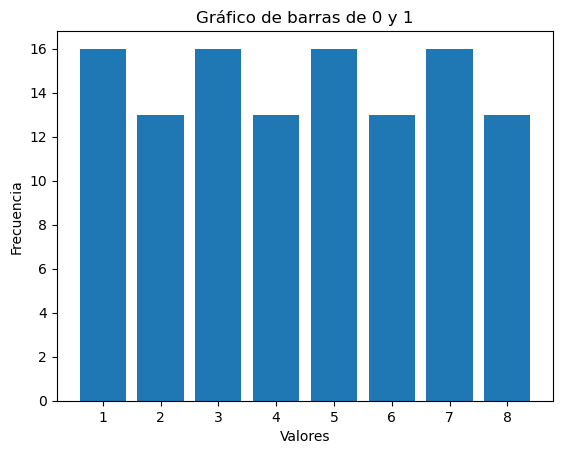

In [7]:
data = []
for archivo in nombres_de_archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_train = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_train)

print(len(df_train))

###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_train["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()


## SIN TL NI OC

In [8]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## CON OC SIN TL

In [9]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    if (sum(labels == 1) != 0):
        recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    else:
        recall_score = 1
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    if(sum(labels == 1) != 0):
        precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    else:
        precision_score = 1
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_oc(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## CON TL SIN OC

In [10]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    if (sum(labels == 1) != 0):
        recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    else:
        recall_score = 1
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    if(sum(labels == 1) != 0):
        precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    else:
        precision_score = 1
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    # print(bin_pred>0.5)
                    # print(bin_label)
                    # print(recall(bin_pred, bin_label))
                    # print(accuracy(bin_pred, bin_label))
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))

    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)

    

## CON TL CON OC

In [11]:
####PRUEBA OPTIMA
###PRIMERO SE REDEFINE LA FUNCIÓN PARA QUE DEVUELVA VALORES EN VEZ DE LAS IMPRESIONES QUE HACE

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    if (sum(labels == 1) != 0):
        recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    else:
        recall_score = 1
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    if(sum(labels == 1) != 0):
        precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    else:
        precision_score = 1
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_oc(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)
       
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Puedes ajustar la media y la desviación estándar según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Puedes ajustar los límites inferior y superior según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Puedes ajustar el parámetro 'gain' según tus necesidades
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##asi se hacen los grupos de parámetros, despues al one cycle lr hay que pasarle exactamente tantos lr como grupos de parámetros
        optimizer = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        ##cuando estan congeladas las capas, solo quiero optimizar la fully connected
        optimizer2 = op( model.fc_binary.parameters(), lr = lr)
        optimizer3 = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        # print(optimizer.param_groups == optimizer2.param_groups)
        # print(optimizer.param_groups == optimizer3.param_groups)
        ##no es igual, el lr pequeño tiene que ser para el top, que es la fully connected


        
        # layer_names = []
        # for idx, (name, param) in enumerate(model.named_parameters()):
        #     layer_names.append(name)
        #     print(f'{idx}: {name}')
        # layer_names.reverse()
        # print('Segundo:', optimizer.param_groups[1])
        total = len(optimizer.param_groups)
        # print(total)
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_freeze)
        # Definir el objeto slice
        lr /= 2
        # lr_slice = slice(lr/100, lr)
        max_lrs = np.linspace(lr/100, lr, total)
        # print(lr_slice.start)
        # print(lr_slice.stop)
        max_lrs = max_lrs.tolist()
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # for i in images:
                #     print(i.shape)
                # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
                # plt.figure(figsize=(10, 10))
                # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
                # plt.axis('off')
                # plt.show()
                # break  # Salir después de mostrar el primer lote
                # Reiniciar gradientes
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    # print(bin_pred>0.5)
                    # print(bin_label)
                    # print(recall(bin_pred, bin_label))
                    # print(accuracy(bin_pred, bin_label))
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## PRUEBAS

### SIN TL NI OC

In [12]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_ct, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_adam')

c:\Users\da01m\anaconda3\envs\tfg_cnn_lv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2024-04-27 19:03:26,631] A new study created in memory with name: no-name-e59aba48-cf1c-4ea7-90a3-938e8c212abe


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 19:06:31,502] Trial 0 finished with values: [1.6571309857114103, 0.7946944516897202, 0.9012500047683716] and parameters: {'batch_size': 32, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 19:09:43,673] Trial 1 finished with values: [202.26301917149686, 0.7810317550599575, 0.7428125143051147] and parameters: {'batch_size': 16, 'lr': 0.01, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-27 20:39:05,237] Trial 28 finished with values: [20.282457740809768, 0.7325595338642598, 0.7606250047683716] and parameters: {'batch_size': 8, 'lr': 0.1, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 20:42:23,056] Trial 29 finished with values: [0.1378357920050621, 0.9445317484438419, 0.9262499809265137] and parameters: {'batch_size': 16, 'lr': 1e-05, 'data_aug': False}. 


5
Best trial:
Value: [0.10481842526467518, 0.961595239341259, 0.9606249928474426]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.07594089836755302, 0.9694404782354832, 0.95374995470047]
Params: 
batch_size: 8
lr: 0.0001
data_aug: False


In [13]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.SGD, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_ct, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_sgd')

[I 2024-04-27 20:42:23,106] A new study created in memory with name: no-name-b8727e7d-5b14-4c77-96e8-ee170f733b63


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 20:45:32,799] Trial 0 finished with values: [0.7134200558066368, 0.5118254056572914, 0.4599999785423279] and parameters: {'batch_size': 16, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 20:48:32,138] Trial 1 finished with values: [6.982111005299958, 0.7922579443454743, 0.8081250190734863] and parameters: {'batch_size': 32, 'lr': 0.1, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-27 22:13:08,066] Trial 28 finished with values: [0.5550948405265809, 0.8048492150008679, 0.6631250381469727] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 22:16:26,532] Trial 29 finished with values: [0.6460828599333763, 0.6721389046311378, 0.4521874785423279] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': False}. 


5
Best trial:
Value: [0.21659850873955294, 0.9163492098450661, 0.9121874570846558]
Params: 
batch_size: 8
lr: 0.01
data_aug: False
Value: [0.16163464002660474, 0.9316666704416277, 0.9084374308586121]
Params: 
batch_size: 16
lr: 0.01
data_aug: False


In [14]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_ct, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_rms')

[I 2024-04-27 22:16:26,560] A new study created in memory with name: no-name-5c1b7d42-07d6-4394-9f41-4ff7c6072498


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 22:19:56,985] Trial 0 finished with values: [1.636727374587208, 0.7513769942522048, 0.6678125262260437] and parameters: {'batch_size': 8, 'lr': 0.1, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 22:23:11,082] Trial 1 finished with values: [23.334698620997365, 0.8061865149438381, 0.7956250309944153] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-27 23:52:52,472] Trial 28 finished with values: [0.17797342344238132, 0.9418412728607655, 0.9284374117851257] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': True}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 23:56:31,343] Trial 29 finished with values: [0.0483873401384335, 0.9813928577303888, 0.9659374952316284] and parameters: {'batch_size': 8, 'lr': 1e-05, 'data_aug': False}. 


5
Best trial:
Value: [0.10930599497518415, 0.9686309538781643, 0.9731249809265137]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.0483873401384335, 0.9813928577303888, 0.9659374952316284]
Params: 
batch_size: 8
lr: 1e-05
data_aug: False


### CON OC SIN TL

In [15]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_oc_adam')

[I 2024-04-27 23:56:31,377] A new study created in memory with name: no-name-aaec8ba9-ad87-4ed3-9f63-369de7edec64


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
5


[I 2024-04-28 00:00:17,945] Trial 0 finished with values: [0.4273665260890266, 0.8742261976003647, 0.86781245470047] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': True}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
5


[I 2024-04-28 00:04:04,199] Trial 1 finished with values: [1.4053601148026065, 0.8144087360799313, 0.8568750619888306] and parameters: {'batch_size': 8, 'lr': 0.01, 'data_aug': True}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 01:33:13,415] Trial 28 finished with values: [0.2973181235976517, 0.8709166713058949, 0.8421875238418579] and parameters: {'batch_size': 32, 'lr': 1e-05, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 01:36:52,389] Trial 29 finished with values: [16.676029212400316, 0.750452389717102, 0.75] and parameters: {'batch_size': 8, 'lr': 0.1, 'data_aug': True}. 


5
Best trial:
Value: [0.09134503108478384, 0.9483055576682091, 0.9503124952316284]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.12901001864025602, 0.9524365098774432, 0.9340624809265137]
Params: 
batch_size: 8
lr: 0.0001
data_aug: False


In [16]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.SGD, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_oc_sgd')

[I 2024-04-28 01:36:52,422] A new study created in memory with name: no-name-b846eaf3-0b03-410b-9e6f-8a9fd5d1dbad


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 01:40:23,528] Trial 0 finished with values: [0.6806934598088265, 0.5811111314594746, 0.3490625023841858] and parameters: {'batch_size': 8, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 01:43:29,553] Trial 1 finished with values: [0.7219826731085778, 0.5213174703717232, 0.7309374809265137] and parameters: {'batch_size': 32, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 03:11:23,743] Trial 28 finished with values: [0.5189770378172398, 0.8320515912771225, 0.7074999809265137] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': False}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 03:14:34,446] Trial 29 finished with values: [43.313473748553065, 0.7898809602856636, 0.7990624308586121] and parameters: {'batch_size': 16, 'lr': 0.1, 'data_aug': False}. 


5
Best trial:
Value: [0.45201877028113807, 0.8662698458135127, 0.8803125619888306]
Params: 
batch_size: 16
lr: 0.01
data_aug: False
Value: [0.1978686859679874, 0.9083412741124631, 0.8665624856948853]
Params: 
batch_size: 8
lr: 0.001
data_aug: False
Value: [0.504951299362292, 0.8409801627695561, 0.8934375047683716]
Params: 
batch_size: 32
lr: 0.01
data_aug: False
Value: [0.7201940548085257, 0.8449206395447254, 0.8956249952316284]
Params: 
batch_size: 16
lr: 0.01
data_aug: True
Value: [0.5753237914391593, 0.8730357193946838, 0.885312557220459]
Params: 
batch_size: 8
lr: 0.01
data_aug: False


In [17]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.RMSprop, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_oc_rms')

[I 2024-04-28 03:14:34,478] A new study created in memory with name: no-name-66d35ed5-b5ce-48d0-a1d5-09b150aeaf8f


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 03:17:49,475] Trial 0 finished with values: [11.00019584060974, 0.832126992046833, 0.8178125619888306] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
5


[I 2024-04-28 03:21:25,346] Trial 1 finished with values: [4.45404306655284, 0.8215793737769127, 0.82750004529953] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': False}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 04:51:30,641] Trial 28 finished with values: [689902712.0842804, 0.6767896907031536, 0.7853125333786011] and parameters: {'batch_size': 32, 'lr': 0.1, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 04:54:48,271] Trial 29 finished with values: [8124293.141832079, 0.6932420732825995, 0.6487500071525574] and parameters: {'batch_size': 16, 'lr': 0.1, 'data_aug': True}. 


5
Best trial:
Value: [0.05838328080368229, 0.9733333344757555, 0.9571875333786011]
Params: 
batch_size: 8
lr: 1e-05
data_aug: False


### CON TL SIN OC

In [18]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_adam')

[I 2024-04-28 04:54:48,308] A new study created in memory with name: no-name-4ac931f3-2158-410a-a55d-aa4c8e1a1efd


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 04:57:54,390] Trial 0 finished with values: [53501.22793647358, 0.7346984238922596, 0.6825000047683716] and parameters: {'batch_size': 16, 'lr': 0.1, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 05:01:22,640] Trial 1 finished with values: [0.1922206514258869, 0.9035000032186508, 0.8696874380111694] and parameters: {'batch_size': 8, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 06:27:22,165] Trial 28 finished with values: [196967456.28615683, 0.708813501894474, 0.7599999308586121] and parameters: {'batch_size': 32, 'lr': 0.1, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 06:30:18,455] Trial 29 finished with values: [0.10098665147219435, 0.9409047652781009, 0.8834375143051147] and parameters: {'batch_size': 32, 'lr': 0.0001, 'data_aug': False}. 


5
Best trial:
Value: [0.15263038182747551, 0.9261111128330232, 0.9515625238418579]
Params: 
batch_size: 8
lr: 1e-05
data_aug: False
Value: [0.10295198585394245, 0.9318333351612091, 0.9087499380111694]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.12207897227650391, 0.9302817484736442, 0.9112499952316284]
Params: 
batch_size: 32
lr: 0.0001
data_aug: True
Value: [0.10641903946336242, 0.9363531775772571, 0.9034374952316284]
Params: 
batch_size: 8
lr: 0.0001
data_aug: False
Value: [0.10098665147219435, 0.9409047652781009, 0.8834375143051147]
Params: 
batch_size: 32
lr: 0.0001
data_aug: False


In [19]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.SGD, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_sgd')

[I 2024-04-28 06:30:18,487] A new study created in memory with name: no-name-eea64a1b-bca2-47c2-80f9-8782fbabfccf


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 06:33:34,914] Trial 0 finished with values: [0.28521206736564636, 0.891980166733265, 0.80531245470047] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 06:36:30,437] Trial 1 finished with values: [0.16945869905641303, 0.9186746063828467, 0.9106249809265137] and parameters: {'batch_size': 32, 'lr': 0.01, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
5


... (52 outputs left out)

[I 2024-04-28 07:59:10,224] Trial 28 finished with values: [0.3156226924061775, 0.8894285784661771, 0.7846875190734863] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 08:02:09,474] Trial 29 finished with values: [0.10980901886941866, 0.9488888914883138, 0.9362500309944153] and parameters: {'batch_size': 16, 'lr': 0.01, 'data_aug': False}. 


5
Best trial:
Value: [0.12131455293601903, 0.9441547645628454, 0.9428125619888306]
Params: 
batch_size: 8
lr: 0.01
data_aug: False
Value: [0.10980901886941866, 0.9488888914883138, 0.9362500309944153]
Params: 
batch_size: 16
lr: 0.01
data_aug: False


In [20]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_rms')

[I 2024-04-28 08:02:09,507] A new study created in memory with name: no-name-fe7bb5b6-d900-45f9-8c7b-b1bc24df4f75


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 08:05:04,050] Trial 0 finished with values: [0.15320412604065498, 0.9239047648012638, 0.8940625190734863] and parameters: {'batch_size': 32, 'lr': 0.0001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 08:08:11,271] Trial 1 finished with values: [0.14191701914183796, 0.9283333367109299, 0.8862500190734863] and parameters: {'batch_size': 16, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 09:33:03,603] Trial 28 finished with values: [0.18937120615431924, 0.9040674638748168, 0.8878124952316284] and parameters: {'batch_size': 32, 'lr': 0.0001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 09:36:11,242] Trial 29 finished with values: [2636.428805867955, 0.703043661415577, 0.7359374761581421] and parameters: {'batch_size': 16, 'lr': 0.01, 'data_aug': True}. 


5
Best trial:
Value: [0.1199979953095317, 0.9376944468915462, 0.9399999380111694]
Params: 
batch_size: 16
lr: 1e-05
data_aug: False
Value: [0.12108483234198501, 0.9412698444724082, 0.8962499499320984]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.1409103565546684, 0.9339047634601594, 0.9653124809265137]
Params: 
batch_size: 32
lr: 1e-05
data_aug: False
Value: [0.10969750927586575, 0.9389841297268868, 0.8981249928474426]
Params: 
batch_size: 8
lr: 1e-05
data_aug: False


### CON TL Y OC

In [21]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_oc_adam')

[I 2024-04-28 09:36:11,274] A new study created in memory with name: no-name-83f14f7e-1148-4a86-a2ef-a2a41edb8d7c


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 09:39:09,235] Trial 0 finished with values: [1.6483428370609907, 0.8893888932466508, 0.8884374499320984] and parameters: {'batch_size': 32, 'lr': 0.01, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 09:42:20,015] Trial 1 finished with values: [0.6210786968469619, 0.662507950514555, 0.573437511920929] and parameters: {'batch_size': 16, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 11:07:43,958] Trial 28 finished with values: [0.15196009619379766, 0.9225436538457871, 0.8946874737739563] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 11:10:49,261] Trial 29 finished with values: [0.31957679214887325, 0.8495555624365807, 0.8621875047683716] and parameters: {'batch_size': 16, 'lr': 0.0001, 'data_aug': True}. 


5
Best trial:
Value: [0.20175265186248, 0.9026230199635028, 0.9018750190734863]
Params: 
batch_size: 32
lr: 0.001
data_aug: True
Value: [0.6165664627582009, 0.8938492107391358, 0.9043749570846558]
Params: 
batch_size: 8
lr: 0.01
data_aug: False
Value: [0.16665741060016442, 0.9255357186496258, 0.8778125047683716]
Params: 
batch_size: 8
lr: 0.001
data_aug: True
Value: [0.5380460084084189, 0.8933373063802719, 0.9071874618530273]
Params: 
batch_size: 16
lr: 0.01
data_aug: False
Value: [0.15196009619379766, 0.9225436538457871, 0.8946874737739563]
Params: 
batch_size: 8
lr: 0.001
data_aug: False


In [22]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, 5, 35, optim.SGD, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_oc_sgd')

[I 2024-04-28 11:10:49,292] A new study created in memory with name: no-name-670c04a6-3272-498d-a686-7e953458f530


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 11:14:03,052] Trial 0 finished with values: [0.7122857394814491, 0.5644801765680313, 0.4318750500679016] and parameters: {'batch_size': 8, 'lr': 1e-05, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 11:17:19,168] Trial 1 finished with values: [0.6303580941259861, 0.6658650898933411, 0.6274999976158142] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 12:42:28,078] Trial 28 finished with values: [0.3313906830921769, 0.8909285777807237, 0.7940624952316284] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 12:45:43,304] Trial 29 finished with values: [0.5535158787667751, 0.7660516010224818, 0.5809375047683716] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': False}. 


5
Best trial:
Value: [0.13388895402560594, 0.955035716742277, 0.9453125]
Params: 
batch_size: 8
lr: 0.01
data_aug: False


In [23]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_oc_rms')

[I 2024-04-28 12:45:43,331] A new study created in memory with name: no-name-73be3b54-9bb7-459c-8003-23de2b50f165


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 12:49:03,008] Trial 0 finished with values: [0.1187752319900028, 0.9461388917267323, 0.9112499952316284] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 12:52:25,563] Trial 1 finished with values: [0.7009829186747083, 0.8717341309785842, 0.8787500262260437] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 14:15:31,356] Trial 28 finished with values: [0.5670908997249353, 0.8986706399917603, 0.903124988079071] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 14:18:35,413] Trial 29 finished with values: [0.1558178697391122, 0.9286825437843799, 0.8846875429153442] and parameters: {'batch_size': 16, 'lr': 0.0001, 'data_aug': True}. 


5
Best trial:
Value: [0.1187752319900028, 0.9461388917267323, 0.9112499952316284]
Params: 
batch_size: 8
lr: 0.0001
data_aug: False
Value: [1.7051460743884668, 0.9055436544120312, 0.9306250810623169]
Params: 
batch_size: 16
lr: 0.001
data_aug: False
Value: [0.1484253077438916, 0.9337698440253736, 0.9274999499320984]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
